# Time-domain science in the LSST era

A dedicated spectroscopic array is most valuable where the bottleneck is telescope time on single
targets: transient classification, rapid multi-messenger response and high-cadence monitoring.
This notebook explores what magnitude and distance limits the nominal 20-telescope array reaches, and
how they move at 10 m and 30 m equivalent apertures.

Assumptions:

* Classification: SNR 5 per R = 300 bin over 450 to 650 nm (SEDM-like, Blagorodnova et al.
  2018), which is SNR 2.04 per native resel; magnitudes in R (Cousins, close to SDSS r).
* Kilonova: AT2017gfo-like, r = 17.3 at 0.5 d at 40 Mpc, fading 0.95 mag per day in r, cooling
  10,000 K to 5000 K to 2500 K at 0.5, 1.5 and 5.5 d (Drout et al. 2017; Shappee et al. 2017).
* SN Ia: $M_B$ = -19.3 at peak, a 10,000 K blackbody ($B-V \approx 0$ at peak, so $B \approx R$), no K-correction; luminosity distance from a
  flat $\Lambda$CDM with $H_0$ = 70, $\Omega_m$ = 0.3.
* TDE: 20,000 K blackbody (TDE optical temperatures are typically a few x 10$^4$ K); monitoring needs SNR 20 per R = 300 bin.
* AGN reverberation: 5100 A continuum precision per epoch from the SNR per resel co-added over a
  50 A window, photon noise only. Fiber spectrophotometric stability is not modelled.
* Sky: the bundled grey-time table (moon up). Dark time is 0.3 to 0.5 mag deeper at the faint end.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
# ---- knobs: array sizes compared throughout (replicated in arrays of 20) ----
from pathlib import Path
SCALES = {20: "nominal 20x (3.2 m eq.)", 200: "10 arrays (10.3 m eq.)", 1720: "86 arrays (30.1 m eq.)"}
NS = np.array([20, 40, 60, 100, 200, 400, 600, 1000, 1720, 2500])
FIG = Path("../memo/figures")          # memo figures land here if the directory exists
def save(fig, name):
    if FIG.is_dir():
        fig.savefig(FIG / name)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 10, "legend.fontsize": 9})
def tel(n, telescopes_per_input=20):
    return Telescope(n_telescopes=int(n), fiber="18um", combine="fiber", telescopes_per_input=telescopes_per_input)
def mark_scales(ax):
    for n in (20, 200, 1720):
        ax.axvline(n, color='0.6', ls='--', lw=0.8)
    ax.set_xscale('log'); ax.set_xlabel("Number of telescopes")
    equivalent_diameter_axis(ax, ticks=(3, 5, 10, 20, 30))

In [3]:
WINDOW = (450, 650); R_BIN = 300; SNR_CLASS = 5; BAND = "R"
def bench(n):
    return LFASTETC("bench_r1800", telescope=tel(n), wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = 1800/R_BIN
snr_resel_class = SNR_CLASS/np.sqrt(k)
sn_like = Source.blackbody(10000, 0, BAND)   # SN Ia near peak, B-V ~ 0

## Classification depth versus array size

How faint of a transient can the array classify in a given exposure, and how does that change with the
array size? The figure below shows the classification depth (SNR = 5 per R = 300 bin over 450-650 nm) for a
SN Ia-like 10,000 K SED in 5, 30 and 60 minutes, against the number of telescopes (equivalent
diameter on the top axis). The horizontal lines mark the discovery depths of the surveys LFAST would
follow up:

* the Argus Array single-epoch (1 min, g = 20.0) and 15-minute co-add (g = 21.5) depths
  (science requirements, 5 sigma, dark time; argus.unc.edu/specifications; Law et al. 2022);
* the LSST single-visit depth (r ~ 24.5; Ivezic et al. 2019).

These are detection limits in g or r (AB). For SN Ia-like colours near peak
$g \approx r$, and R (Vega) is ~0.2 mag brighter than r (AB); both offsets are ignored here.

A classifier that cannot reach a survey's discovery depth leaves its faintest transients
unclassified, so the distance between the curves and these lines is the number to watch.

,N=20,N=200,N=1720
exposure (min),,,
5,19.9,21.2,22.4
30,21.1,22.4,23.6
60,21.5,22.8,24.0


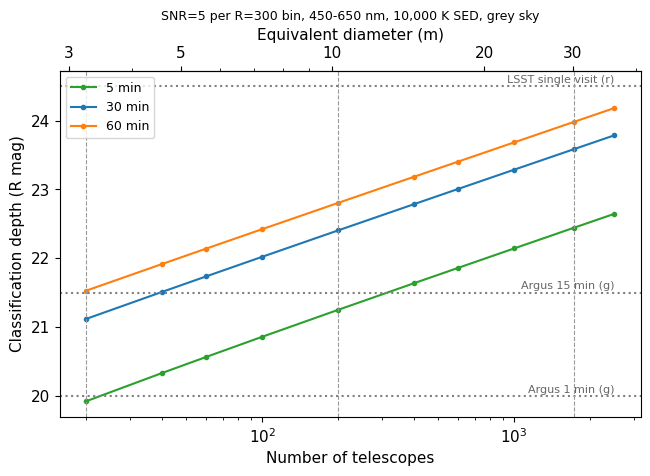

In [4]:
REFS = {"Argus 1 min (g)": 20.0, "Argus 15 min (g)": 21.5, "LSST single visit (r)": 24.5}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
depth = {}
for exp, color in ((300, 'C2'), (1800, 'C0'), (3600, 'C1')):
    d = np.array([bench(int(n)).limiting_magnitude(sn_like, exp, snr_resel_class, wavelength=WINDOW) for n in NS])
    depth[exp] = dict(zip(NS, d))
    ax.plot(NS, d, marker='o', ms=3, color=color, label=f"{exp/60:.0f} min")
for txt, mag in REFS.items():
    ax.axhline(mag, color='0.5', ls=':'); ax.text(NS[-1], mag+0.05, txt, fontsize=8, color='0.4', ha='right')
ax.set_ylabel("Classification depth (R mag)")
ax.set_title("SNR=5 per R=300 bin, 450-650 nm, 10,000 K SED, grey sky", fontsize=9); ax.legend(loc='upper left')
mark_scales(ax)
save(fig, "classification_depth_vs_N.pdf")
pd.DataFrame({f"N={n}": {exp // 60: depth[exp][n] for exp in depth} for n in SCALES}).rename_axis("exposure (min)").style.format("{:.1f}").set_caption("Classification depth (R mag, SNR=5 per R=300 bin)")

The nominal array classifies to R ~ 21.1 in 30 min and R ~ 21.5 in 60 min, i.e. down to the Argus
15-minute co-add depth only with 1 hr exposure time. Ten arrays (200 telescopes) nearly reach that depth
in 5 min (R ~ 21.2) and go 1.3 mag beyond it in 60 min (R ~ 22.8); 86 arrays reach R ~ 24.0 in
60 min, within ~0.5 mag of the LSST single-visit depth.

## Kilonova horizon

We can also investigate the distance at which an AT2017gfo-like kilonova can still be classified (30 min exposure) at
0.5, 1, 2 and 3 days after merger, as a function of the array size. The shaded bands are the LIGO binary-neutron-star ranges:
150-170 Mpc in O4 and 225-295 Mpc planned for O5 (LVK observing plan G2002127-v37, Oct 2026).
The right-hand axis gives the same distances as a distance modulus; the legend gives, for each
epoch, the kilonova's apparent R magnitude at the 20-telescope horizon (its classification limit).

,N=20,N=200,N=1720
days after merger,,,
0.5,232,420,722
1,177,321,552
2,99,179,308
3,60,108,186


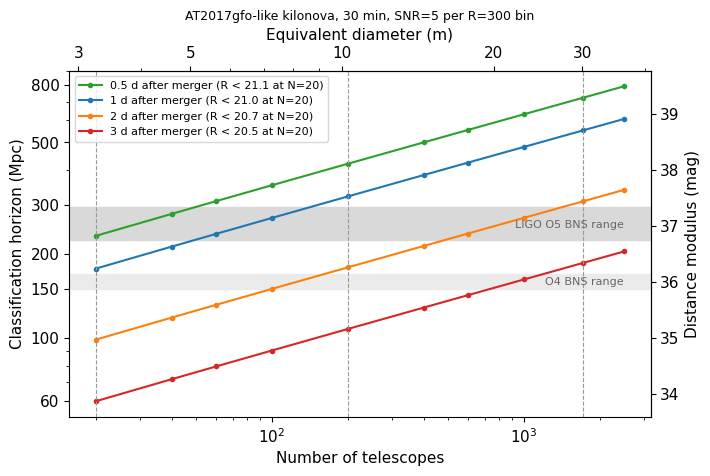

In [5]:
def kn_src(day):
    teff = np.interp(day, [0.5, 1.5, 5.5], [10000, 5000, 2500])
    return Source.blackbody(teff, 0, BAND)
def kn_mag_40(day):
    return 17.3 + 0.95*(day-0.5)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
horizon = {}
for day, color in ((0.5, 'C2'), (1, 'C0'), (2, 'C1'), (3, 'C3')):
    lim = np.array([bench(int(n)).limiting_magnitude(kn_src(day), 1800, snr_resel_class, wavelength=WINDOW) for n in NS])
    D = 40*10**((lim - kn_mag_40(day))/5)
    horizon[day] = dict(zip(NS, D))
    ax.plot(NS, D, marker='o', ms=3, color=color, label=f"{day} d after merger (R < {lim[0]:.1f} at N=20)")
ax.axhspan(225, 295, color='0.85', zorder=0); ax.text(NS[-1], 255, "LIGO O5 BNS range", fontsize=8, color='0.4', ha='right', va='center')
ax.axhspan(150, 170, color='0.92', zorder=0); ax.text(NS[-1], 159, "O4 BNS range", fontsize=8, color='0.4', ha='right', va='center')
ax.set_yscale('log'); ax.set_ylabel("Classification horizon (Mpc)")
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter, NullLocator
ticks_mpc = [60, 100, 150, 200, 300, 500, 800]
ax.yaxis.set_major_locator(FixedLocator(ticks_mpc)); ax.yaxis.set_major_formatter(FixedFormatter([str(t) for t in ticks_mpc]))
ax.yaxis.set_minor_formatter(NullFormatter())
mu_ax = ax.secondary_yaxis('right', functions=(lambda d: 5*np.log10(np.clip(d, 1e-3, None)) + 25,
                                               lambda mu: 10**((mu - 25)/5)))
mu_ax.yaxis.set_major_locator(FixedLocator(range(34, 40))); mu_ax.yaxis.set_major_formatter(FixedFormatter([str(m) for m in range(34, 40)]))
mu_ax.yaxis.set_minor_locator(NullLocator()); mu_ax.set_ylabel("Distance modulus (mag)")
ax.set_title("AT2017gfo-like kilonova, 30 min, SNR=5 per R=300 bin", fontsize=9); ax.legend(fontsize=8, loc='upper left')
mark_scales(ax)
save(fig, "kilonova_horizon_vs_N.pdf")
pd.DataFrame({f"N={n}": {f"{day:g}": horizon[day][n] for day in horizon} for n in SCALES}).rename_axis("days after merger").style.format("{:.0f}").set_caption("Kilonova classification horizon (Mpc, 30 min exposure)")

The nominal array classifies a kilonova out to ~230 Mpc at 0.5 d and ~180 Mpc at 1 d, which covers
the O4 range on the first night. Ten arrays push the 1-day horizon to ~320 Mpc, beyond the planned O5
(single facility) range. The kilonova fades and cools fast: at every array size the 3-day horizon is about a third of
the 1-day one.

## SN Ia classification redshift reach

Maximum redshift at which a SN Ia can be classified at peak (solid) and one magnitude past peak
(dashed). B is taken equal to R ($B-V \approx 0$ at peak for the 10,000 K SED) and the K-correction is
ignored, so treat the
redshifts beyond about 0.3 as indicative.

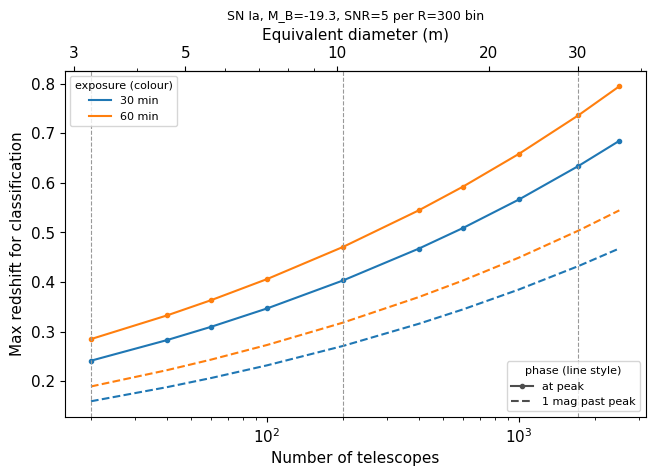

In [6]:
from astropy.cosmology import FlatLambdaCDM
from matplotlib.lines import Line2D
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
zs = np.linspace(0.01, 1.2, 600)
m_peak = -19.3 + cosmo.distmod(zs).value
fig, ax = plt.subplots(figsize=(7.5, 4.5))
zreach = {}
for exp, color in ((1800, 'C0'), (3600, 'C1')):
    zr = []
    for n in NS:
        lim = bench(int(n)).limiting_magnitude(sn_like, exp, snr_resel_class, wavelength=WINDOW)
        zr.append((np.interp(lim, m_peak, zs), np.interp(lim - 1, m_peak, zs)))
    zr = np.array(zr)
    zreach[(exp // 60, "at peak")] = dict(zip(NS, zr[:, 0]))
    zreach[(exp // 60, "peak + 1 mag")] = dict(zip(NS, zr[:, 1]))
    ax.plot(NS, zr[:, 0], marker='o', ms=3, color=color)
    ax.plot(NS, zr[:, 1], ls='--', color=color)
ax.set_ylabel("Max redshift for classification")
ax.set_title("SN Ia, M_B=-19.3, SNR=5 per R=300 bin", fontsize=9)
colour_legend = ax.legend([Line2D([], [], color='C0'), Line2D([], [], color='C1')], ["30 min", "60 min"],
                          title="exposure (colour)", fontsize=8, title_fontsize=8, loc='upper left')
ax.add_artist(colour_legend)
ax.legend([Line2D([], [], color='0.3', marker='o', ms=3), Line2D([], [], color='0.3', ls='--')], ["at peak", "1 mag past peak"],
          title="phase (line style)", fontsize=8, title_fontsize=8, loc='lower right')
mark_scales(ax)
save(fig, "snia_zreach_vs_N.pdf")
z_table = pd.DataFrame({f"N={n}": {key: zreach[key][n] for key in zreach} for n in SCALES}).round(2)
z_table.index.names = ["exposure (min)", "phase"]
z_table.style.format("{:.2f}").set_caption("SN Ia: maximum redshift for classification")

In 30 minutes the nominal array classifies SNe Ia at peak to z ~ 0.24 (z ~ 0.16 one magnitude past
peak). Ten arrays reach z ~ 0.40 and 86 arrays z ~ 0.63; doubling the exposure to 60 minutes adds
only ~0.05-0.1 in redshift.

## TDE monitoring

Tidal disruption events stay bright and blue (~20,000 K) for months, and their broad H and He II
lines evolve over weeks, so a useful programme takes a spectrum every week or so. We ask for SNR 20
per R = 300 bin, enough to follow the shape and strength of the broad lines, and compute the time
per epoch for TDEs at R = 18-21.

In [7]:
tde = Source.blackbody(20000, 0, BAND)
snr_resel_mon = 20/np.sqrt(k)
tde_mags = (18, 19, 20, 21)
pd.DataFrame({f"N={n}": dict(zip([f"R={m}" for m in tde_mags],
                                 bench(n).exptime_vs_mag(tde, tde_mags, snr=snr_resel_mon, wavelength=WINDOW)/60))
              for n in SCALES}).T.rename_axis("array size").style.format("{:.1f}").set_caption("TDE monitoring: exposure time per epoch (min, SNR=20 per R=300 bin)")

,R=18,R=19,R=20,R=21
array size,,,,
N=20,3.9,13.0,53.6,271.9
N=200,0.7,2.0,6.7,29.1
N=1720,0.2,0.5,1.4,4.7


For the nominal array a TDE at R = 18-19 costs 4-13 minutes per epoch, so weekly spectra of several
TDEs are cheap. At R = 20 an epoch takes about 55 minutes, and R = 21 (~4.5 h) is out of reach. Ten
arrays bring R = 20 down to ~7 minutes and R = 21 to ~30 minutes; 86 arrays do R = 21 in ~5 minutes,
which opens up the much larger sample of fainter TDEs that LSST will find.

## AGN reverberation mapping: continuum precision per epoch

Reverberation campaigns need nightly spectrophotometry at the 1 to 2% level over months. The
table gives the photon-noise precision on the 5100 A continuum (50 A window) per 10 minute epoch
for Seyferts at V = 14 to 17.

In [8]:
agn = Source.powerlaw(-0.5, 0, "V", system="AB")
WIN_A = 50; CENTER_NM = 510.0                               # the "50 A window at 5100 A"
lo, hi = CENTER_NM - WIN_A/20, CENTER_NM + WIN_A/20          # 10 A per nm, half-width each side
agn_mags = (14, 15, 16, 17)
rows = {}
for n in SCALES:
    e = LFASTETC("bench_r1800", telescope=tel(n))
    row = {}
    for m in agn_mags:
        r = e.snr(agn.with_mag(m), 600)
        win = (r.wavelength >= lo) & (r.wavelength <= hi)
        # information sum over the resels: the SNR of one common amplitude fitted against the
        # known continuum shape, (sum_i SNR_i^2)^(1/2); not the SNR of an unweighted flux sum
        snr50 = np.sqrt(np.nansum(r.snr[win]**2))
        row[f"V={m}"] = 100/snr50
    rows[f"N={n}"] = row
pd.DataFrame(rows).T.rename_axis("array size").style.format("{:.2f}").set_caption("AGN: 5100 A continuum precision per 10-min epoch (%, photon noise only)")

,V=14,V=15,V=16,V=17
array size,,,,
N=20,0.23,0.37,0.60,1.01
N=200,0.07,0.12,0.19,0.32
N=1720,0.03,0.04,0.07,0.11


Photon noise is never the limit here: even the nominal array reaches 0.6% per 10 minutes at
V = 16, several times better than campaigns need. What limits reverberation mapping is the
night-to-night flux calibration. Fiber-coupling and seeing losses change from night to night, and
campaigns normally remove them by scaling every spectrum to the narrow [O III] 5007 A line, whose flux
is constant over the campaign (van Groningen & Wanders 1992). How well that works for a
fiber-combined array is the real question for this programme, but is beyond the scope of this notebook.